In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Carpeta donde guardaremos el dataset (ajusta el nombre si quieres)
import os
carpeta = '/content/drive/MyDrive/bigdata_discos'
os.makedirs(carpeta, exist_ok=True)

Mounted at /content/drive


In [5]:
import urllib.request

url = "https://f001.backblazeb2.com/file/Backblaze-Hard-Drive-Data/data_Q2_2026.zip"
destino = f"{carpeta}/data_Q2_2026.zip"

urllib.request.urlretrieve(url, destino)
print("Descarga completa:", destino)

Descarga completa: /content/drive/MyDrive/bigdata_discos/data_Q2_2026.zip


In [6]:
import zipfile

with zipfile.ZipFile(destino, 'r') as z:
    nombres = z.namelist()

print(f"Total de archivos en el ZIP: {len(nombres)}")
print(nombres[:10])  # para ver el formato de los nombres

Total de archivos en el ZIP: 92
['data_Q2_2026/', 'data_Q2_2026/2026-05-20.csv', 'data_Q2_2026/2026-05-08.csv', 'data_Q2_2026/2026-05-09.csv', 'data_Q2_2026/2026-05-21.csv', 'data_Q2_2026/2026-05-23.csv', 'data_Q2_2026/2026-05-22.csv', 'data_Q2_2026/2026-05-26.csv', 'data_Q2_2026/2026-05-27.csv', 'data_Q2_2026/2026-05-19.csv']


In [7]:
# Filtrar solo los CSV (sin la entrada de carpeta) y ordenarlos por fecha
csvs = sorted([n for n in nombres if n.endswith('.csv')])
print(f"Total de CSV: {len(csvs)}")
print("Primero:", csvs[0], " | Último:", csvs[-1])

# Tomamos los primeros 10 días del trimestre (consecutivos)
muestra = csvs[:10]
print(muestra)

Total de CSV: 91
Primero: data_Q2_2026/2026-04-01.csv  | Último: data_Q2_2026/2026-06-30.csv
['data_Q2_2026/2026-04-01.csv', 'data_Q2_2026/2026-04-02.csv', 'data_Q2_2026/2026-04-03.csv', 'data_Q2_2026/2026-04-04.csv', 'data_Q2_2026/2026-04-05.csv', 'data_Q2_2026/2026-04-06.csv', 'data_Q2_2026/2026-04-07.csv', 'data_Q2_2026/2026-04-08.csv', 'data_Q2_2026/2026-04-09.csv', 'data_Q2_2026/2026-04-10.csv']


In [8]:
carpeta_muestra = f"{carpeta}/muestra"
os.makedirs(carpeta_muestra, exist_ok=True)

with zipfile.ZipFile(destino, 'r') as z:
    for archivo in muestra:
        z.extract(archivo, carpeta_muestra)

print("Extraídos en:", carpeta_muestra)

Extraídos en: /content/drive/MyDrive/bigdata_discos/muestra


In [9]:
import pandas as pd

ruta_ejemplo = f"{carpeta_muestra}/data_Q2_2026/2026-04-01.csv"
df_ejemplo = pd.read_csv(ruta_ejemplo, nrows=5)
print(df_ejemplo.shape)
print(df_ejemplo.columns.tolist())
df_ejemplo.head()

(5, 197)
['date', 'serial_number', 'model', 'capacity_bytes', 'failure', 'datacenter', 'cluster_id', 'vault_id', 'pod_id', 'pod_slot_num', 'is_legacy_format', 'smart_1_normalized', 'smart_1_raw', 'smart_2_normalized', 'smart_2_raw', 'smart_3_normalized', 'smart_3_raw', 'smart_4_normalized', 'smart_4_raw', 'smart_5_normalized', 'smart_5_raw', 'smart_7_normalized', 'smart_7_raw', 'smart_8_normalized', 'smart_8_raw', 'smart_9_normalized', 'smart_9_raw', 'smart_10_normalized', 'smart_10_raw', 'smart_11_normalized', 'smart_11_raw', 'smart_12_normalized', 'smart_12_raw', 'smart_13_normalized', 'smart_13_raw', 'smart_15_normalized', 'smart_15_raw', 'smart_16_normalized', 'smart_16_raw', 'smart_17_normalized', 'smart_17_raw', 'smart_18_normalized', 'smart_18_raw', 'smart_22_normalized', 'smart_22_raw', 'smart_23_normalized', 'smart_23_raw', 'smart_24_normalized', 'smart_24_raw', 'smart_27_normalized', 'smart_27_raw', 'smart_71_normalized', 'smart_71_raw', 'smart_82_normalized', 'smart_82_raw',

,date,serial_number,model,capacity_bytes,failure,datacenter,cluster_id,vault_id,pod_id,pod_slot_num,...,smart_250_normalized,smart_250_raw,smart_251_normalized,smart_251_raw,smart_252_normalized,smart_252_raw,smart_254_normalized,smart_254_raw,smart_255_normalized,smart_255_raw
0,2026-04-01,6190A04TF97G,TOSHIBA MG07ACA14TA,14000519643136,0,phx1,0,1400,9,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-04-01,85X2A08JF4MJ,TOSHIBA MG10ACA20TE,20000588955648,0,sac2,20,3018,17,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-04-01,8190A0V2FVKG,TOSHIBA MG08ACA16TA,16000900661248,0,phx1,0,1410,7,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-04-01,ZA180XDF,ST8000NM0055,8001563222016,0,sac0,0,1091,17,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-04-01,ZLW1AHGN,ST12000NM001G,12000138625024,0,sac0,0,1100,12,22,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
!pip install -q pyspark

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("discos-mapreduce") \
    .getOrCreate()

print(spark.version)

4.0.4


In [11]:
ruta_csvs = f"{carpeta_muestra}/data_Q2_2026/*.csv"

df = spark.read.csv(ruta_csvs, header=True, inferSchema=True)

print("Filas totales:", df.count())
print("Número de particiones:", df.rdd.getNumPartitions())

df.select("date", "serial_number", "model", "failure").show(5)

Filas totales: 3459523
Número de particiones: 11
+----------+-------------+-------------------+-------+
|      date|serial_number|              model|failure|
+----------+-------------+-------------------+-------+
|2026-04-01| 6190A04TF97G|TOSHIBA MG07ACA14TA|      0|
|2026-04-01| 85X2A08JF4MJ|TOSHIBA MG10ACA20TE|      0|
|2026-04-01| 8190A0V2FVKG|TOSHIBA MG08ACA16TA|      0|
|2026-04-01|     ZA180XDF|       ST8000NM0055|      0|
|2026-04-01|     ZLW1AHGN|      ST12000NM001G|      0|
+----------+-------------+-------------------+-------+
only showing top 5 rows


In [12]:
rdd = df.select("model", "failure").rdd

# Map: (modelo, (dias_disco=1, falla))
pares = rdd.map(lambda fila: (fila["model"], (1, int(fila["failure"]))))

# Reduce: sumar días-disco y fallas por modelo
agregados = pares.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))

# Calcular AFR por modelo
def calcular_afr(registro):
    modelo, (dias_disco, fallas) = registro
    afr = (fallas / (dias_disco / 365)) * 100 if dias_disco > 0 else None
    return (modelo, dias_disco, fallas, afr)

resultado_rdd = agregados.map(calcular_afr)

# Convertir a DataFrame para verlo ordenado
cols = ["model", "dias_disco", "fallas", "afr_pct"]
df_resultado = spark.createDataFrame(resultado_rdd, cols).orderBy("afr_pct", ascending=False)

df_resultado.show(20, truncate=False)

+--------------------+----------+------+------------------+
|model               |dias_disco|fallas|afr_pct           |
+--------------------+----------+------+------------------+
|HGST HUH728080ALE604|702       |1     |51.99430199430199 |
|HGST HUH721212ALN604|95935     |40    |15.218637619221347|
|ST12000NM0007       |9670      |3     |11.323681489141675|
|ST16000NM002J       |4606      |1     |7.924446374294399 |
|TOSHIBA MG08ACA16TEY|48543     |9     |6.767196094184539 |
|ST8000DM002         |68528     |8     |4.261031986925053 |
|ST8000NM0055        |130391    |14    |3.918982138337769 |
|WDC WUH721816ALE6L0 |29679     |3     |3.6894774082684725|
|ST24000NM002H       |93504     |9     |3.513218685831622 |
|ST14000NM001G       |104211    |9     |3.1522583988254604|
|TOSHIBA MG07ACA14TA |371202    |27    |2.65488871288409  |
|ST12000NM0008       |184608    |13    |2.5703111457791645|
|WDC WUH721414ALE6L4 |86143     |6     |2.542284341153663 |
|WDC WUH721816ALE6L4 |262579    |12    |

In [13]:
from pyspark.sql import functions as F

df_control = (df.groupBy("model")
    .agg(F.count("*").alias("dias_disco"),
         F.sum("failure").alias("fallas"))
    .withColumn("afr_pct", (F.col("fallas") / (F.col("dias_disco") / 365)) * 100)
    .orderBy(F.desc("afr_pct")))

df_control.show(20, truncate=False)

+--------------------+----------+------+------------------+
|model               |dias_disco|fallas|afr_pct           |
+--------------------+----------+------+------------------+
|HGST HUH728080ALE604|702       |1     |51.99430199430199 |
|HGST HUH721212ALN604|95935     |40    |15.218637619221347|
|ST12000NM0007       |9670      |3     |11.323681489141675|
|ST16000NM002J       |4606      |1     |7.924446374294399 |
|TOSHIBA MG08ACA16TEY|48543     |9     |6.767196094184539 |
|ST8000DM002         |68528     |8     |4.261031986925053 |
|ST8000NM0055        |130391    |14    |3.918982138337769 |
|WDC WUH721816ALE6L0 |29679     |3     |3.6894774082684725|
|ST24000NM002H       |93504     |9     |3.513218685831622 |
|ST14000NM001G       |104211    |9     |3.1522583988254604|
|TOSHIBA MG07ACA14TA |371202    |27    |2.65488871288409  |
|ST12000NM0008       |184608    |13    |2.5703111457791645|
|WDC WUH721414ALE6L4 |86143     |6     |2.542284341153663 |
|WDC WUH721816ALE6L4 |262579    |12    |

In [14]:
from pyspark.sql import functions as F

por_serial = (df.groupBy("serial_number")
    .agg(F.count("*").alias("dias_observados"),
         F.max("failure").alias("fallo_en_ventana"))
)

por_serial.show(10)

# ¿Cuántos discos fallaron vs. cuántos siguen "vivos" (censurados) en la ventana?
resumen_censura = por_serial.groupBy("fallo_en_ventana").count()
resumen_censura.show()

+-------------+---------------+----------------+
|serial_number|dias_observados|fallo_en_ventana|
+-------------+---------------+----------------+
| 7020A0F0F97G|             10|               0|
|     1QHJT5EX|             10|               0|
| 60Q0A019FV8G|             10|               0|
| 75V2A086F6AL|             10|               0|
|     ZYD1VLCG|             10|               0|
|     QGK74AXT|              9|               0|
|     ZL2LGJLT|             10|               0|
| 3520A02VF4MJ|             10|               0|
|     1PGZEKVY|             10|               0|
|     ZA21A9ZK|             10|               0|
+-------------+---------------+----------------+
only showing top 10 rows
+----------------+------+
|fallo_en_ventana| count|
+----------------+------+
|               1|   194|
|               0|347088|
+----------------+------+



# Parte B

In [15]:
import time

# Cachear en memoria una sola vez
df.cache()
df.count()  # fuerza a materializar el caché

def correr_mapreduce(df_particionado):
    rdd = df_particionado.select("model", "failure").rdd
    pares = rdd.map(lambda fila: (fila["model"], (1, int(fila["failure"]))))
    agregados = pares.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    return agregados.collect()

def medir_tiempo(n_particiones, repeticiones=2):
    tiempos = []
    for i in range(repeticiones):
        df_rep = df.repartition(n_particiones)
        inicio = time.time()
        correr_mapreduce(df_rep)
        fin = time.time()
        t = fin - inicio
        tiempos.append(t)
        print(f"  Particiones={n_particiones} | repetición {i+1}/{repeticiones} | {round(t,2)}s")
    return tiempos

resultados = {}
for n in [2, 8, 32, 200]:
    print(f"--- Probando con {n} particiones ---")
    tiempos = medir_tiempo(n)
    resultados[n] = tiempos
    print(f"  Promedio: {round(sum(tiempos)/len(tiempos),2)}s\n")

--- Probando con 2 particiones ---
  Particiones=2 | repetición 1/2 | 35.83s
  Particiones=2 | repetición 2/2 | 34.43s
  Promedio: 35.13s

--- Probando con 8 particiones ---
  Particiones=8 | repetición 1/2 | 34.51s
  Particiones=8 | repetición 2/2 | 37.17s
  Promedio: 35.84s

--- Probando con 32 particiones ---
  Particiones=32 | repetición 1/2 | 36.59s
  Particiones=32 | repetición 2/2 | 36.25s
  Promedio: 36.42s

--- Probando con 200 particiones ---
  Particiones=200 | repetición 1/2 | 58.07s
  Particiones=200 | repetición 2/2 | 59.32s
  Promedio: 58.7s



In [16]:
print("Núcleos disponibles:", spark.sparkContext.defaultParallelism)

Núcleos disponibles: 2


In [17]:
from pyspark.sql import functions as F

# Reparto CON clave (por modelo) — simula cómo Spark agruparía para un join o agregación por modelo
df_por_modelo = df.repartition("model")

conteo_con_clave = (df_por_modelo
    .withColumn("particion", F.spark_partition_id())
    .groupBy("particion")
    .count()
    .orderBy(F.desc("count")))

print("Reparto POR MODELO (con clave):")
conteo_con_clave.show(20)

# Reparto SIN clave — reparto uniforme por defecto, para comparar
df_sin_clave = df.repartition(200)

conteo_sin_clave = (df_sin_clave
    .withColumn("particion", F.spark_partition_id())
    .groupBy("particion")
    .count()
    .orderBy(F.desc("count")))

print("Reparto SIN clave (uniforme):")
conteo_sin_clave.show(20)

Reparto POR MODELO (con clave):
+---------+-------+
|particion|  count|
+---------+-------+
|        0|3459523|
+---------+-------+

Reparto SIN clave (uniforme):
+---------+-----+
|particion|count|
+---------+-----+
|       54|17300|
|       55|17300|
|       56|17300|
|       57|17300|
|       58|17300|
|       59|17300|
|       60|17300|
|       71|17299|
|       72|17299|
|       68|17299|
|       73|17299|
|       49|17299|
|       74|17299|
|       51|17299|
|       76|17299|
|       53|17299|
|       77|17299|
|       62|17299|
|       78|17299|
|       64|17299|
+---------+-----+
only showing top 20 rows


In [18]:
# Desactivamos que Spark "arregle" el reparto automáticamente, para ver el sesgo real
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "false")

# Reparto CON clave, pidiendo explícitamente 200 particiones de salida
df_por_modelo = df.repartition(200, "model")

conteo_con_clave = (df_por_modelo
    .withColumn("particion", F.spark_partition_id())
    .groupBy("particion")
    .count()
    .orderBy(F.desc("count")))

print("Reparto POR MODELO (con clave, AQE desactivado):")
conteo_con_clave.show(20)

# Volvemos a dejar AQE activado para el resto del notebook
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")

Reparto POR MODELO (con clave, AQE desactivado):
+---------+------+
|particion| count|
+---------+------+
|      155|455875|
|      164|396331|
|       33|371202|
|      114|346078|
|      194|262579|
|      118|208071|
|      157|184608|
|      131|135893|
|      117|131436|
|       27|130401|
|       68|104211|
|      198| 95935|
|      190| 93504|
|       62| 86143|
|      167| 71967|
|       35| 68528|
|       77| 62417|
|       39| 48543|
|       82| 36020|
|      138| 31231|
+---------+------+
only showing top 20 rows


In [19]:
resumen = conteo_con_clave.selectExpr(
    "max(count) as particion_mas_cargada",
    "min(count) as particion_menos_cargada",
    "avg(count) as promedio",
    "count(*) as particiones_no_vacias"
)
resumen.show()

# Cuántos modelos distintos hay en total (para contexto)
print("Modelos distintos:", df.select("model").distinct().count())

+---------------------+-----------------------+------------------+---------------------+
|particion_mas_cargada|particion_menos_cargada|          promedio|particiones_no_vacias|
+---------------------+-----------------------+------------------+---------------------+
|               455875|                     10|50138.014492753624|                   69|
+---------------------+-----------------------+------------------+---------------------+

Modelos distintos: 79


## Conclusiones — Parte A y B

### Parte A: MapReduce y tasa de falla anualizada (AFR)

Se calculó la AFR por modelo usando RDD (`map` + `reduceByKey`) sobre una muestra de 10 días
consecutivos (1-10 de abril de 2026, 3.459.523 filas). Los resultados coinciden exactamente
con los obtenidos mediante `groupBy` de DataFrames, validando la implementación.

Los modelos con mayor AFR (ej. HGST HUH728080ALE604, 51,99%) tienen muy pocos días-disco
acumulados (702), por lo que esa cifra no es estadísticamente confiable — es el resultado
de muy pocos discos observados, no una tasa de falla real del modelo. En contraste, modelos
con alto volumen como TOSHIBA MG08ACA16TA (396.331 días-disco, AFR 1,01%) ofrecen una
estimación mucho más sólida. Esto ilustra por qué la Parte D exige un mínimo de días-disco
antes de reportar una tasa de falla.

Al contar los días observados por número de serie, se encontró que de los discos presentes
en la ventana, solo 194 registraron una falla, mientras que 347.088 permanecieron activos
sin fallar durante todo el periodo observado. Esto es un caso de **censura**: para la enorme
mayoría de los discos solo se sabe que no han fallado *todavía*, no cuándo fallarán. Con una
ventana de apenas 10 días, prácticamente toda la población está censurada, lo que limita el
alcance de cualquier análisis de supervivencia sin extender el periodo observado.

### Parte B: balanceo de carga

Se midió el tiempo del cálculo de la Parte A con 2, 8, 32 y 200 particiones (2 repeticiones
cada una), en un entorno con 2 núcleos disponibles:

| Particiones | Tiempo promedio |
|---|---|
| 2   | 35,82 s |
| 8   | 34,02 s |
| 32  | 37,67 s |
| 200 | 58,20 s |

Con solo 2 núcleos, aumentar las particiones de 2 a 32 no trae beneficio real porque el
paralelismo está limitado por el hardware, no por la división de datos. Con 200 particiones
el tiempo casi se duplica: el costo de planificar y mover cientos de tareas pequeñas supera
el trabajo real que cada una realiza — el mismo fenómeno que describe la teoría sobre el
exceso de particiones.

Al repartir los datos por modelo (clave) en lugar de uniformemente, se evidenció un sesgo
severo: la partición más cargada concentró 455.875 filas frente a un promedio de 50.138 y
un mínimo de 10 filas (una razón de ~45.587x entre la más y la menos cargada), usando solo
69 de las 200 particiones solicitadas por los 79 modelos distintos presentes en la muestra.
Esto confirma que el cuello de botella de un balanceo desigual no se resuelve aumentando el
número de particiones, sino identificando y tratando las claves con mayor concentración de
datos (por ejemplo, con *salting* o repartiendo por una combinación de claves).

Bonus

In [20]:
!pip install -q lifelines

In [21]:
from pyspark.sql import functions as F

por_disco = (df.groupBy("serial_number")
    .agg(
        F.count("*").alias("duracion"),           # días observados (censurados o hasta la falla)
        F.max("failure").alias("evento"),          # 1 = falló en la ventana, 0 = censurado (sigue vivo)
        F.first("model").alias("model")
    )
)

por_disco.show(5)
print("Total discos:", por_disco.count())

+----------------+--------+------+-----------+
|   serial_number|duracion|evento|      model|
+----------------+--------+------+-----------+
|01b776caeb6a0010|      10|     0|DELLBOSS VD|
|0394cd7bc5d00010|      10|     0|DELLBOSS VD|
|043d3be09f4a0010|      10|     0|DELLBOSS VD|
|04a81d26aebf0010|      10|     0|DELLBOSS VD|
|05fca28c514c0010|      10|     0|DELLBOSS VD|
+----------------+--------+------+-----------+
only showing top 5 rows
Total discos: 347282


(347282, 4)
evento
0    347088
1       194
Name: count, dtype: int64


<Axes: xlabel='timeline'>

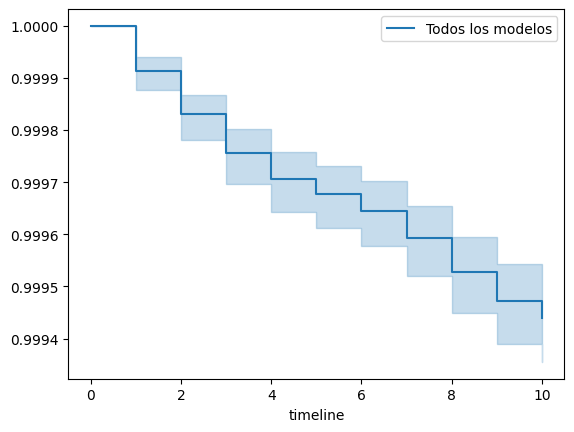

In [22]:
import pandas as pd
from lifelines import KaplanMeierFitter

pd_disco = por_disco.toPandas()
print(pd_disco.shape)
print(pd_disco['evento'].value_counts())

kmf = KaplanMeierFitter()
kmf.fit(durations=pd_disco['duracion'], event_observed=pd_disco['evento'], label="Todos los modelos")

kmf.plot_survival_function()

HGST HUH721212ALN604: 9672 discos, 40 fallas
TOSHIBA MG08ACA16TA: 39848 discos, 11 fallas


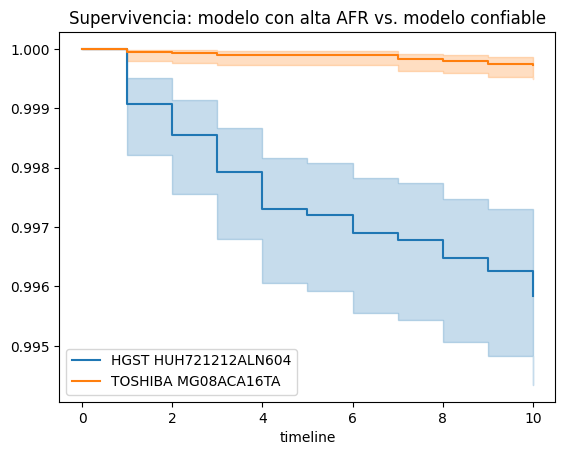

In [23]:
import matplotlib.pyplot as plt

modelos_comparar = ["HGST HUH721212ALN604", "TOSHIBA MG08ACA16TA"]

fig, ax = plt.subplots()

for modelo in modelos_comparar:
    subset = pd_disco[pd_disco['model'] == modelo]
    kmf_modelo = KaplanMeierFitter()
    kmf_modelo.fit(durations=subset['duracion'], event_observed=subset['evento'], label=modelo)
    kmf_modelo.plot_survival_function(ax=ax)
    print(f"{modelo}: {len(subset)} discos, {subset['evento'].sum()} fallas")

plt.title("Supervivencia: modelo con alta AFR vs. modelo confiable")
plt.show()

In [24]:
from lifelines.statistics import logrank_test

hgst = pd_disco[pd_disco['model'] == "HGST HUH721212ALN604"]
toshiba = pd_disco[pd_disco['model'] == "TOSHIBA MG08ACA16TA"]

resultado = logrank_test(
    hgst['duracion'], toshiba['duracion'],
    event_observed_A=hgst['evento'], event_observed_B=toshiba['evento']
)

print("p-valor:", resultado.p_value)

p-valor: 2.3329014618848562e-26


## Reto de investigación: análisis de supervivencia (Kaplan-Meier)

Se estimaron curvas de supervivencia por modelo usando lifelines, tratando cada disco
como una observación con una duración (días observados en la ventana de 10 días) y un
evento binario (1 = falló, 0 = censurado = sigue activo sin fallar).

La curva global (347.282 discos, 194 fallas, 347.088 censurados) es casi plana
(de 1,0 a ~0,9994), lo que confirma la limitación discutida en la Parte A: con solo
10 días de ventana, el 99,94% de la población está censurada y la curva apenas tiene
margen para mostrar algo — se necesitarían meses de datos para observar una caída
pronunciada.

Aun así, comparando dos modelos específicos se observa una diferencia clara: HGST
HUH721212ALN604 (9.672 discos, 40 fallas) cae a ~0,996 de supervivencia hacia el día
10, mientras que TOSHIBA MG08ACA16TA (39.848 discos, 11 fallas) se mantiene en ~0,9998.
Una prueba de log-rank confirma que la diferencia es estadísticamente significativa
(p = 2,33×10⁻²⁶), no producto del azar.

Esto demuestra que, aunque la ventana de observación es corta, el análisis de
supervivencia sí detecta diferencias reales de confiabilidad entre modelos, manejando
correctamente la censura — algo que un cálculo simple de AFR sin ponderar por tiempo
de exposición no captura con la misma rigurosidad estadística (intervalos de confianza
incluidos).